In [1]:
print("Welcome to my Stock Market Analysis Project!")
print("Let's explore historical stock market data.")


Welcome to my Stock Market Analysis Project!
Let's explore historical stock market data.


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("All libraries imported successfully!")


All libraries imported successfully!


pandas for organizing stock prices in tables.
numpy for performing mathematical calculations.
matplotlib.pyplot for creating stock-price graphs.

**Loading Historical Stock Data**

In [3]:
!pip -q install yfinance

import yfinance as yf

stock_symbol = "AAPL"

stock_data = yf.download(
    stock_symbol,
    period="1y",
    interval="1d",
    auto_adjust=True,
    progress=False
)

print("Stock data downloaded successfully!")


Stock data downloaded successfully!


yfinance is a Python library that helps retrieve historical stock market data from Yahoo Finance.The -q means quiet: it reduces installation messages.A stock symbol, also called a ticker, is a short code used to identify a company's stock.stock_data =
Stores the downloaded information in a variable named stock_data.


stock_symbol
Tells Python which stock we want. Currently, that's Apple.


period="1y"
Requests data covering approximately one year.


interval="1d"
Requests one observation per trading day, rather than every minute.


auto_adjust=True
Requests prices adjusted for relevant stock splits and dividends.


progress=False
Hides the download progress indicator.

***Exploring Historical Stock Data***

In [4]:
# Display the first 5 rows of stock data
stock_data.head()


Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2025-10-17,251.361465,252.447465,246.359952,247.107192,49147000
2025-10-20,261.274841,263.406980,254.689183,254.948221,90483000
2025-10-21,261.802917,264.313663,260.866375,260.916209,46695900
2025-10-22,257.498810,261.882610,254.489905,261.683334,45015300
2025-10-23,258.624634,259.660815,257.060435,258.983325,32754900


Open
The stock's opening price for that trading day.



High
The highest price reached during that trading day.

Low
The lowest price reached during that trading day.



Close
The closing price at the end of the trading day, adjusted for relevant corporate actions in our downloaded data.



Volume
The number of shares traded during the day.

***Checking the Size of Stock Data***

In [5]:
# Check the number of rows and columns
print("Shape of stock data:", stock_data.shape)

# Check the column names
print("Column names:", stock_data.columns.tolist())

Shape of stock data: (251, 5)
Column names: [('Close', 'AAPL'), ('High', 'AAPL'), ('Low', 'AAPL'), ('Open', 'AAPL'), ('Volume', 'AAPL')]


***Checking Missing Values***

In [6]:
# Check for missing values in each column
print("Missing values in each column:")
print(stock_data.isnull().sum())

Missing values in each column:
Price   Ticker
Close   AAPL      0
High    AAPL      0
Low     AAPL      0
Open    AAPL      0
Volume  AAPL      0
dtype: int64


***Visualizing Historical Stock Prices***

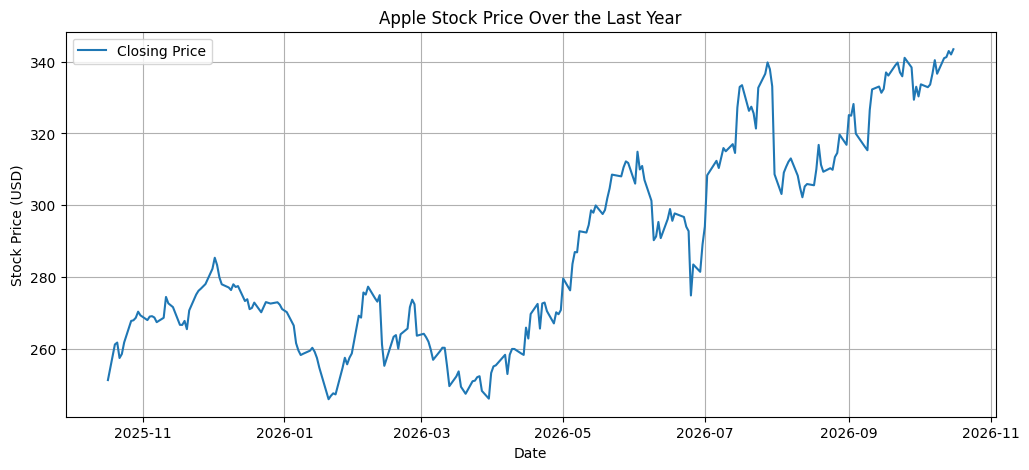

In [7]:
# Plot the historical closing prices
plt.figure(figsize=(12, 5))

plt.plot(stock_data["Close"], label="Closing Price")

plt.title("Apple Stock Price Over the Last Year")
plt.xlabel("Date")
plt.ylabel("Stock Price (USD)")

plt.legend()
plt.grid(True)
plt.show()

***Analyzing Stock Trends Using Moving Averages***

In [8]:
# Calculate 20-day and 50-day moving averages
stock_data["MA20"] = stock_data["Close"].rolling(window=20).mean()
stock_data["MA50"] = stock_data["Close"].rolling(window=50).mean()

# Display the latest values
stock_data[["Close", "MA20", "MA50"]].tail()

Price,Close,MA20,MA50
Ticker,AAPL,,
Date,,,
2026-10-12,340.970001,335.783504,323.003097
2026-10-13,341.269989,336.280003,323.765325
2026-10-14,342.959991,336.807503,324.442257
2026-10-15,342.000000,337.057503,325.067617
2026-10-16,343.459991,337.424002,325.694000


MA20 calculates the average closing price over the latest 20 trading days.



MA50 calculates the average closing price over the latest 50 trading days.



.rolling(window=20) creates a moving window of 20 observations.



.mean() calculates the average within that window.



.tail() displays the last five rows by default.

***Stock Price vs Moving Averages***

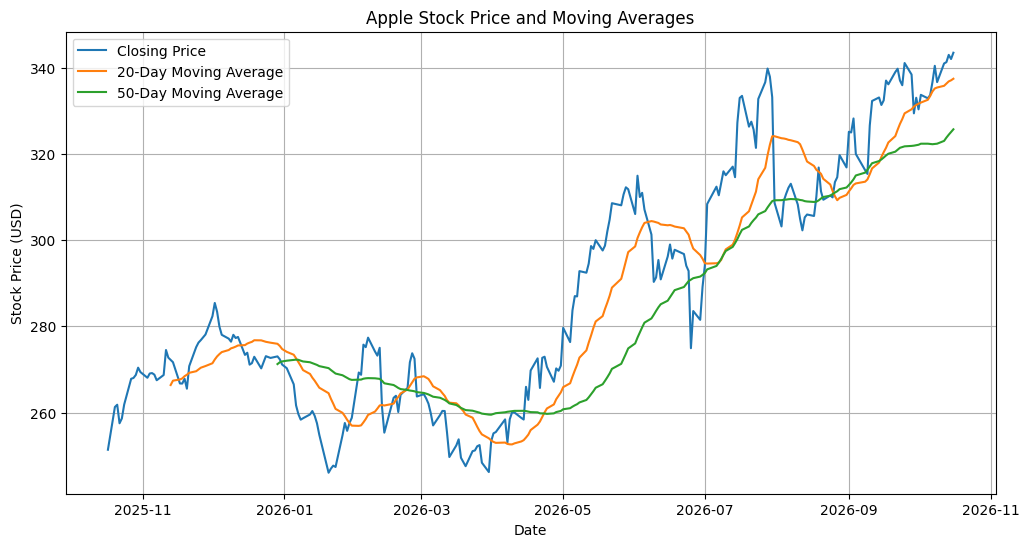

In [9]:
# Create a graph comparing stock prices and moving averages
plt.figure(figsize=(12, 6))

plt.plot(stock_data["Close"], label="Closing Price")
plt.plot(stock_data["MA20"], label="20-Day Moving Average")
plt.plot(stock_data["MA50"], label="50-Day Moving Average")

plt.title("Apple Stock Price and Moving Averages")
plt.xlabel("Date")
plt.ylabel("Stock Price (USD)")

plt.legend()
plt.grid(True)
plt.show()

***Calculating Daily Stock Returns***

In [11]:
# Calculate daily percentage returns
stock_data["Daily Return"] = stock_data["Close"].pct_change() * 100

# Display the latest 5 daily returns
stock_data[["Close", "Daily Return"]].tail()

Price,Close,Daily Return
Ticker,AAPL,
Date,,
2026-10-12,340.970001,NaN
2026-10-13,341.269989,NaN
2026-10-14,342.959991,NaN
2026-10-15,342.000000,NaN
2026-10-16,343.459991,NaN


***Daily Stock Return Visualization***

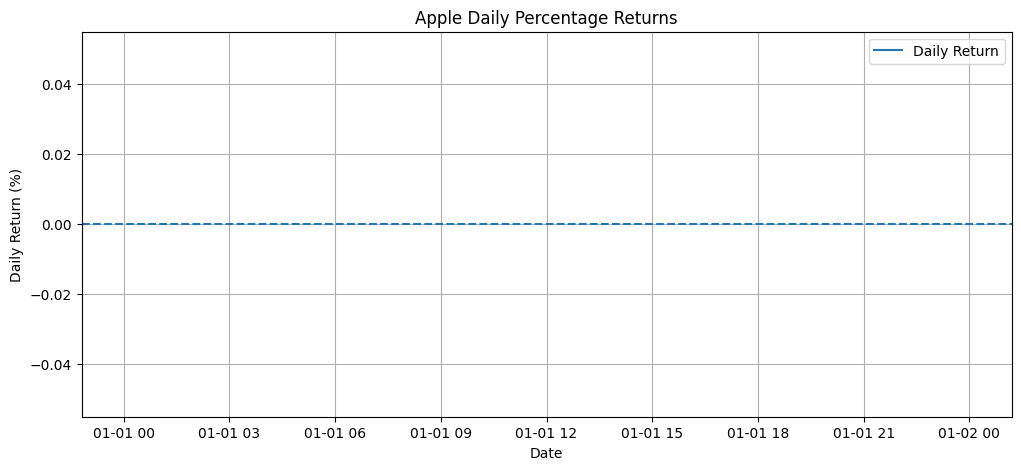

In [12]:
# Plot daily percentage returns
plt.figure(figsize=(12, 5))

plt.plot(stock_data["Daily Return"], label="Daily Return")

plt.axhline(y=0, linestyle="--")

plt.title("Apple Daily Percentage Returns")
plt.xlabel("Date")
plt.ylabel("Daily Return (%)")

plt.legend()
plt.grid(True)
plt.show()

In [13]:
# Check whether daily returns have different values
print(stock_data["Daily Return"].describe())

# Display some daily return values
print(stock_data["Daily Return"].head(10))

# Check how many unique return values exist
print("Unique return values:", stock_data["Daily Return"].nunique())

count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: Daily Return, dtype: float64
Date
2025-10-17   NaN
2025-10-20   NaN
2025-10-21   NaN
2025-10-22   NaN
2025-10-23   NaN
2025-10-24   NaN
2025-10-27   NaN
2025-10-28   NaN
2025-10-29   NaN
2025-10-30   NaN
Name: Daily Return, dtype: float64
Unique return values: 0


In [14]:
# Check whether closing prices are available
print("Closing prices:")
print(stock_data["Close"].head(10))

# Count missing closing prices
print("\nMissing closing prices:")
print(stock_data["Close"].isnull().sum())

# Count valid closing prices
print("\nValid closing prices:")
print(stock_data["Close"].notnull().sum())

Closing prices:
Ticker            AAPL
Date                  
2025-10-17  251.361465
2025-10-20  261.274841
2025-10-21  261.802917
2025-10-22  257.498810
2025-10-23  258.624634
2025-10-24  261.852722
2025-10-27  267.820679
2025-10-28  268.009979
2025-10-29  268.707397
2025-10-30  270.401123

Missing closing prices:
Ticker
AAPL    0
dtype: int64

Valid closing prices:
Ticker
AAPL    251
dtype: int64


In [15]:
# Extract the Apple closing prices as a simple Series
closing_prices = stock_data["Close"]["AAPL"]

# Recalculate daily percentage returns
stock_data["Daily Return"] = closing_prices.pct_change() * 100

# Display the results
print(stock_data["Daily Return"].head(10))

Date
2025-10-17         NaN
2025-10-20    3.943873
2025-10-21    0.202115
2025-10-22   -1.644026
2025-10-23    0.437215
2025-10-24    1.248175
2025-10-27    2.279127
2025-10-28    0.070682
2025-10-29    0.260221
2025-10-30    0.630323
Name: Daily Return, dtype: float64


In [16]:
print(stock_data["Daily Return"].describe())
print(stock_data["Daily Return"].head(10))

count    250.000000
mean       0.136764
std        1.536899
min       -7.353858
25%       -0.666552
50%        0.130224
75%        0.932768
max        4.840675
Name: Daily Return, dtype: float64
Date
2025-10-17         NaN
2025-10-20    3.943873
2025-10-21    0.202115
2025-10-22   -1.644026
2025-10-23    0.437215
2025-10-24    1.248175
2025-10-27    2.279127
2025-10-28    0.070682
2025-10-29    0.260221
2025-10-30    0.630323
Name: Daily Return, dtype: float64


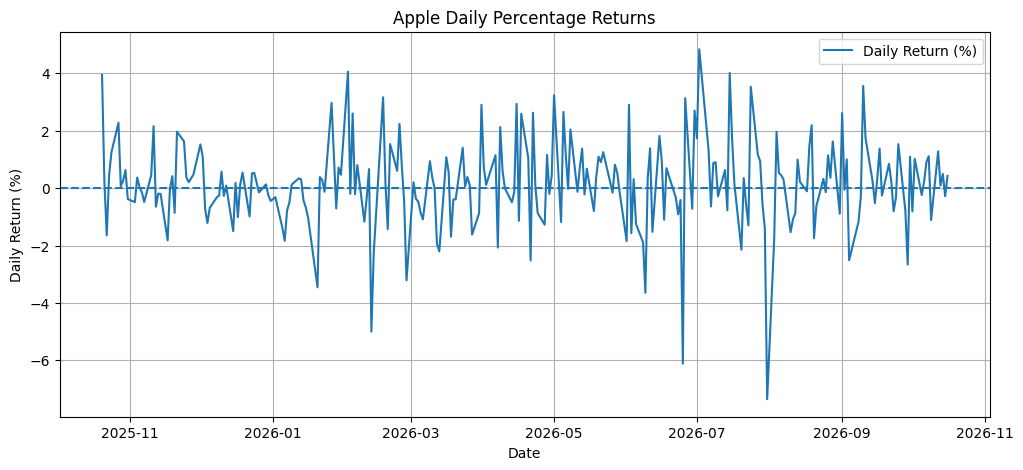

In [17]:
# Plot the corrected daily percentage returns
plt.figure(figsize=(12, 5))

plt.plot(
    stock_data.index,
    stock_data["Daily Return"],
    label="Daily Return (%)"
)

plt.axhline(y=0, linestyle="--")
plt.title("Apple Daily Percentage Returns")
plt.xlabel("Date")
plt.ylabel("Daily Return (%)")

plt.legend()
plt.grid(True)
plt.show()

***Calculating Stock Volatility***

What is volatility?
Volatility describes how much stock returns fluctuate. Higher volatility means returns have varied more; lower volatility means they have varied less. It doesn't tell us which direction the price will move next.

In [19]:
# Calculate the standard deviation of daily returns
daily_volatility = stock_data["Daily Return"].std()

print("Daily Volatility:", round(daily_volatility, 2), "%")

Daily Volatility: 1.54 %


# **Preparing Data for Machine Learning**

In [20]:
# Create a dataset for next-day price prediction
model_data = stock_data[["Close"]].copy()

# Use today's closing price to predict the next trading day's price
model_data["Next Day Close"] = model_data["Close"].shift(-1)

# Display the first 5 rows
model_data.head()

Price,Close,Next Day Close
Ticker,AAPL,
Date,,
2025-10-17,251.361465,261.274841
2025-10-20,261.274841,261.802917
2025-10-21,261.802917,257.498810
2025-10-22,257.498810,258.624634
2025-10-23,258.624634,261.852722


***Splitting Data into Training and Testing Sets***

A machine-learning model needs historical examples to learn from. We then test it on later data it hasn't seen during training.
We'll use the earlier 80% of the data for training and the later 20% for testing. For time-series data, we should preserve chronological order instead of randomly shuffling the rows.

In [21]:
# Remove the final row, which has no next-day target
model_data = model_data.dropna()

# Separate the input feature and prediction target
X = model_data[["Close"]]
y = model_data["Next Day Close"]

# Split chronologically: first 80% for training, last 20% for testing
split_index = int(len(model_data) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 200
Testing rows: 50


***Training the Stock Price Prediction Model***

Linear regression learns a relationship between an input and a target value. Here, it will learn the relationship between today's closing price and the next trading day's closing price.

In [22]:
# Import the machine learning model
from sklearn.linear_model import LinearRegression

# Create the model
model = LinearRegression()

# Train the model using historical training data
model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


***Predicting Next-Day Closing Prices***

In [23]:
# Predict next-day closing prices using the test data
y_pred = model.predict(X_test)

# Compare actual prices with predicted prices
results = pd.DataFrame({
    "Actual Price": y_test,
    "Predicted Price": y_pred
})

# Display the first 10 comparisons
print(results.head(10).round(2))

            Actual Price  Predicted Price
Date                                     
2026-08-06        313.06           311.80
2026-08-07        308.26           312.70
2026-08-10        304.91           308.00
2026-08-11        302.25           304.71
2026-08-12        305.26           302.10
2026-08-13        305.93           305.05
2026-08-14        305.59           305.71
2026-08-17        310.03           305.38
2026-08-18        316.83           309.73
2026-08-19        311.30           316.40


***Evaluating the Prediction Model***

We'll calculate two metrics: Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE).

In [24]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("Mean Absolute Error (MAE):", round(mae, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))

Mean Absolute Error (MAE): 3.16
Root Mean Squared Error (RMSE): 4.05


# ***Actual vs Predicted Stock Prices***

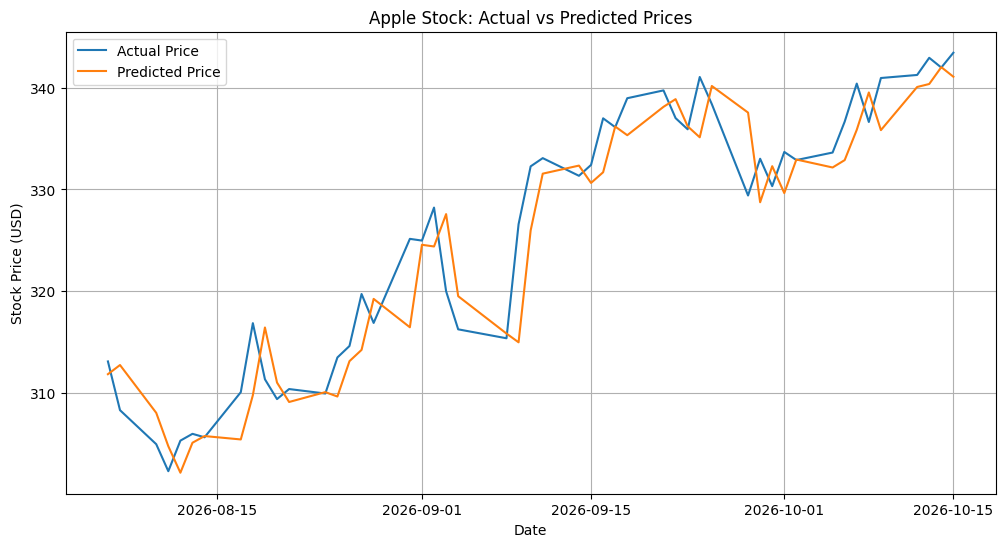

In [25]:
# Plot actual and predicted prices
plt.figure(figsize=(12, 6))

plt.plot(y_test.index, y_test, label="Actual Price")
plt.plot(y_test.index, y_pred, label="Predicted Price")

plt.title("Apple Stock: Actual vs Predicted Prices")
plt.xlabel("Date")
plt.ylabel("Stock Price (USD)")

plt.legend()
plt.grid(True)
plt.show()

# **Conclusion**

In this project, I analyzed historical Apple (AAPL) stock market data using Python, Pandas, NumPy, Matplotlib, and Scikit-learn.

I explored historical closing prices, calculated 20-day and 50-day moving averages, analyzed daily percentage returns and volatility, and visualized stock price trends. I also developed a basic Linear Regression model to estimate next-day closing prices using previous closing prices.

The model was evaluated using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE), along with a comparison of actual and predicted prices.

This project helped me understand data preprocessing, exploratory data analysis, data visualization, machine learning, and model evaluation. The model is a beginner-level educational experiment and is not intended for real-world trading decisions.

**Author:** Yashika Sharma